In [25]:
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [26]:
df = pd.read_csv("spam.csv", encoding="latin-1")

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [27]:
df.columns

Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')

In [28]:
df = df[['v1', 'v2']]

df.columns = ['label', 'message']

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [29]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


label      0
message    0
dtype: int64

In [30]:
df = df.dropna()

In [31]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 403


In [32]:
df = df.drop_duplicates()

In [33]:
print(df['label'].value_counts())
print(df['label'].value_counts(normalize=True) * 100)

label
ham     4516
spam     653
Name: count, dtype: int64
label
ham     87.366996
spam    12.633004
Name: proportion, dtype: float64


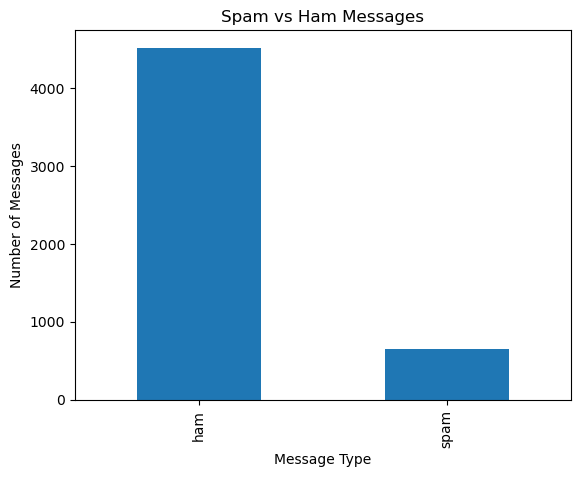

In [34]:
df['label'].value_counts().plot(kind='bar')

plt.title("Spam vs Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.show()

## Class Distribution

The dataset contains two classes:

- Ham: legitimate messages
- Spam: unwanted or fraudulent messages

The class distribution is important because an imbalanced dataset can make accuracy misleading. Therefore, precision, recall, and F1-score are also considered during evaluation.

In [35]:
df['label_num'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

df.head()

,label,message,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [38]:
def preprocess_text(text):
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove numbers
    text = re.sub(r'\d+', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [39]:
df['clean_message'] = df['message'].apply(preprocess_text)

In [40]:
df[['message', 'clean_message']].head(10)

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling its been weeks now a...
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnaminun...
8,WINNER!! As a valued network customer you have...,winner as a valued network customer you have b...
9,Had your mobile 11 months or more? U R entitle...,had your mobile months or more u r entitled to...


In [41]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sanya\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [43]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

In [44]:
def preprocess_text(text):
    text = text.lower()

    text = re.sub(r'http\S+|www\S+|https\S+', '', text)

    text = text.translate(str.maketrans('', '', string.punctuation))

    text = re.sub(r'\d+', '', text)

    words = text.split()

    words = [word for word in words if word not in stop_words]

    return ' '.join(words)

In [45]:
df['clean_message'] = df['message'].apply(preprocess_text)

In [46]:
X = df['clean_message']
y = df['label_num']

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [48]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4135
Testing samples: 1034


## TF-IDF Feature Extraction

TF-IDF stands for Term Frequency-Inverse Document Frequency.

It converts text into numerical features that machine learning algorithms can understand.

TF-IDF gives higher importance to words that occur frequently in a particular message but are relatively uncommon across the entire dataset.

For example, common words such as "the" may receive a low TF-IDF value, while words strongly associated with spam such as "free", "winner", or "prize" may receive higher values.

TF-IDF consists of:

- TF (Term Frequency): how frequently a word occurs in a document.
- IDF (Inverse Document Frequency): how rare the word is across all documents.

Therefore, TF-IDF helps the model identify words that are more useful for distinguishing spam from legitimate messages.

In [49]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

In [50]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [51]:
print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (4135, 5000)
Testing shape: (1034, 5000)


In [52]:
# Model 1 — Multinomial Naive Bayes
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [53]:
y_pred_nb = nb_model.predict(X_test_tfidf)

In [54]:
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb))
print("Recall:", recall_score(y_test, y_pred_nb))
print("F1 Score:", f1_score(y_test, y_pred_nb))

Accuracy: 0.965183752417795
Precision: 0.9896907216494846
Recall: 0.732824427480916
F1 Score: 0.8421052631578947


In [55]:
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=['Ham', 'Spam']
))

              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       0.99      0.73      0.84       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.91      1034
weighted avg       0.97      0.97      0.96      1034



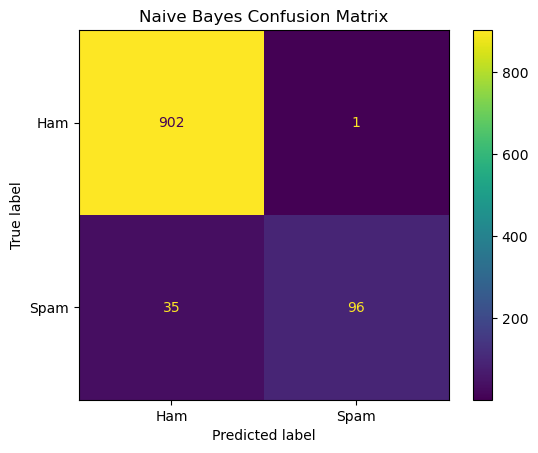

In [56]:
cm_nb = confusion_matrix(y_test, y_pred_nb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=['Ham', 'Spam']
)

disp.plot()
plt.title("Naive Bayes Confusion Matrix")
plt.show()

In [57]:
# model2 - Logistic Regression
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [58]:
y_pred_lr = lr_model.predict(X_test_tfidf)

In [59]:
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))

Accuracy: 0.9564796905222437
Precision: 0.9886363636363636
Recall: 0.6641221374045801
F1 Score: 0.7945205479452054


In [60]:
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=['Ham', 'Spam']
))

              precision    recall  f1-score   support

         Ham       0.95      1.00      0.98       903
        Spam       0.99      0.66      0.79       131

    accuracy                           0.96      1034
   macro avg       0.97      0.83      0.89      1034
weighted avg       0.96      0.96      0.95      1034



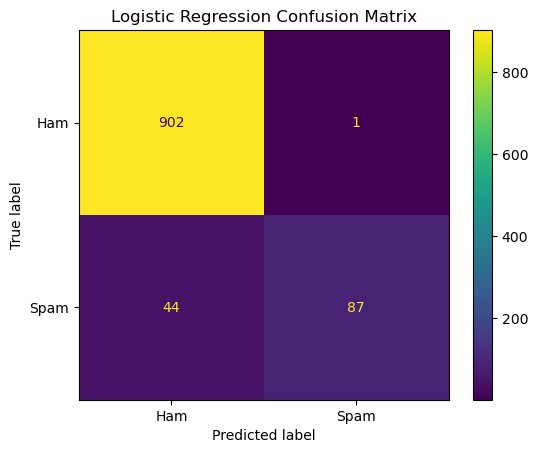

In [61]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=['Ham', 'Spam']
)

disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [62]:
results = pd.DataFrame({
    'Model': ['Multinomial Naive Bayes', 'Logistic Regression'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_lr)
    ],
    'Precision': [
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_lr)
    ],
    'Recall': [
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_lr)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_lr)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Multinomial Naive Bayes,0.965184,0.989691,0.732824,0.842105
1,Logistic Regression,0.956480,0.988636,0.664122,0.794521


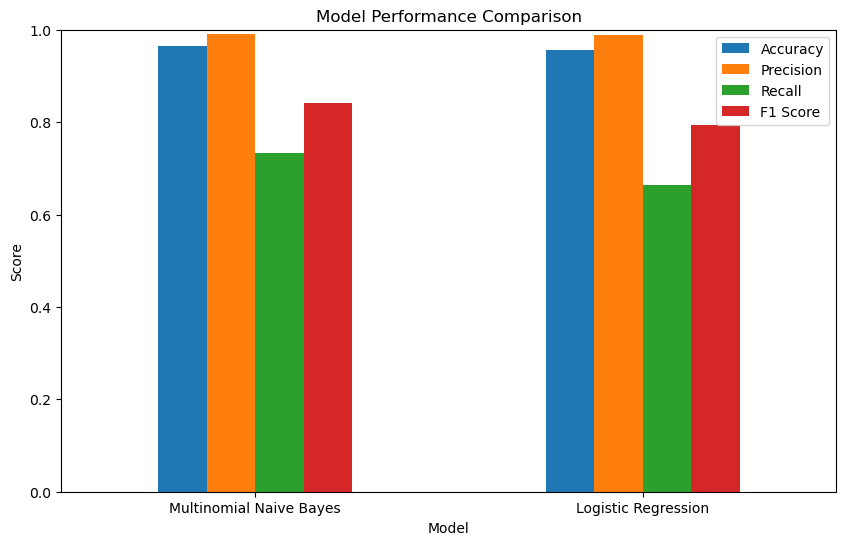

In [63]:
results.set_index('Model').plot(kind='bar', figsize=(10, 6))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

## Why is Recall Important for Spam Detection?

Recall is particularly important because it measures how many actual spam messages are correctly identified by the model.

A false negative occurs when a spam message is incorrectly classified as ham.

For example, if 100 messages are actually spam and the model identifies only 80 of them as spam, the remaining 20 spam messages are false negatives.

A high recall means that the model catches most of the actual spam messages.

However, precision is also important because incorrectly classifying legitimate messages as spam can cause users to miss important emails or messages.

Therefore, a good spam detection system should aim for a strong balance between precision and recall, which is represented by the F1-score.

In [64]:
!pip install wordcloud

In [65]:
from wordcloud import WordCloud

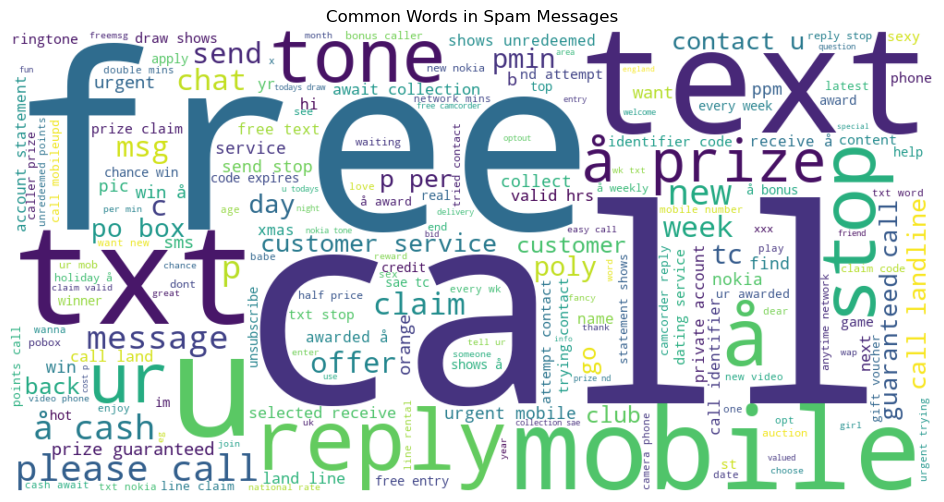

In [66]:
spam_text = ' '.join(
    df[df['label'] == 'spam']['clean_message']
)

spam_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(spam_text)

plt.figure(figsize=(12, 6))
plt.imshow(spam_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Common Words in Spam Messages")
plt.show()

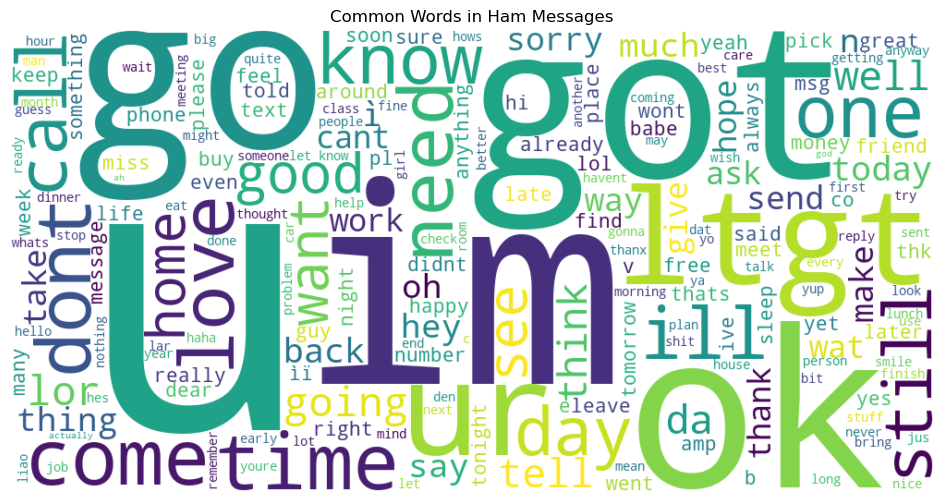

In [67]:
ham_text = ' '.join(
    df[df['label'] == 'ham']['clean_message']
)

ham_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(ham_text)

plt.figure(figsize=(12, 6))
plt.imshow(ham_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Common Words in Ham Messages")
plt.show()

In [68]:
def predict_message(message, model=nb_model):
    cleaned = preprocess_text(message)

    vector = tfidf.transform([cleaned])

    prediction = model.predict(vector)[0]

    if prediction == 1:
        return "SPAM"
    else:
        return "HAM"

In [69]:
predict_message(
    "Congratulations! You have won a free lottery ticket. Click now!"
)

'SPAM'

In [70]:
predict_message(
    "Hey, are we meeting for lunch today?"
)

'HAM'

In [71]:
messages = [
    "Congratulations! You have won a free prize. Click now!",
    "Can you send me the assignment?",
    "URGENT! You won a cash reward!",
    "Hey, what time are you coming home?"
]

for message in messages:
    print(message)
    print("Prediction:", predict_message(message))
    print()

Congratulations! You have won a free prize. Click now!
Prediction: SPAM

Can you send me the assignment?
Prediction: HAM

URGENT! You won a cash reward!
Prediction: SPAM

Hey, what time are you coming home?
Prediction: HAM



## Conclusion

In this project, an NLP-based binary classification system was developed to distinguish spam messages from legitimate messages.

The text data was cleaned using preprocessing techniques such as lowercasing, punctuation removal, number removal, and stopword removal. TF-IDF was then used to convert text into numerical features.

Two machine learning models were trained and evaluated:

1. Multinomial Naive Bayes
2. Logistic Regression

The models were evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

The project demonstrates how traditional machine learning and NLP techniques can be used to build an effective spam detection system. Recall and precision are particularly important because both missed spam messages and incorrectly blocked legitimate messages can negatively affect users.